# Secondary Leagues: factor analysis, outliers and clustering

### IMPORTS

In [ ]:
#Necessary Installs
!pip install factor_analyzer
!pip install pingouin pandas numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 1.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor_analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42655 sha256=791aac9cba63049da83a3dcc84de38027ad83d42f73f54b5210039206efbfede
  Stored in directory: /root/.cache/pip/wheels/a2/af/06/f4d4ed4d9d714fda437fb1583629417319603c2266e7b233cc
Successfully built factor_analyzer
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.4/204.4 kB 5.0 MB/s eta 0:00:00


In [ ]:
#Necessary Imports
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from factor_analyzer.factor_analyzer import calculate_kmo
from factor_analyzer.rotator import Rotator
from factor_analyzer import FactorAnalyzer
import pingouin as pg
from numpy.linalg import inv
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity

In [ ]:
!pip install feature-engine

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 4.4 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.preprocessing import StandardScaler
from feature_engine.outliers import Winsorizer
from sklearn.cluster import KMeans
from sklearn.metrics import explained_variance_score

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
import plotly.express as px

### Exploratory Analysis + FA

In [ ]:
#Import data

df_8 = pd.read_excel("LOW5.xlsx", sheet_name="Sheet1", index_col = "Player")
df_8

,Gls/90,Sh,G/Sh,G-xG,Ast,A-xAG,KP,PPA,CrsPA,SCA,GCA,Att 3rd,Tkl+Int,Att Pen,TOSucc,PrgC,Mis,Dis,On-Off,AeWon
Player,,,,,,,,,,,,,,,,,,,,
Anders Dreyer,0.20,2.75,0.07,-0.08,0.33,0.05,2.48,2.09,0.65,4.51,0.52,0.13,0.72,4.58,0.39,1.90,1.96,0.78,0.56,0.00
Andi Zeqiri,0.47,2.88,0.07,-0.06,0.10,-0.03,0.68,0.31,0.05,2.04,0.21,0.16,0.84,4.61,0.47,1.31,2.72,1.62,0.66,2.41
Andri Guðjohnsen,0.29,1.50,0.19,0.09,0.07,-0.06,0.64,0.64,0.00,1.79,0.14,0.36,0.86,3.86,0.57,1.14,2.86,1.29,-0.30,2.71
Antoine Bernier,0.16,1.62,0.10,-0.01,0.16,-0.05,1.57,1.14,0.32,3.89,0.38,0.65,2.54,4.32,1.19,3.03,2.11,1.46,1.19,0.70
Aurélien Scheidler,0.36,2.47,0.15,-0.01,0.12,0.01,0.84,0.42,0.00,1.81,0.12,0.06,0.78,5.00,0.78,0.84,2.65,1.20,-0.32,6.20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Vangelis Pavlidis,0.76,3.23,0.20,0.02,0.28,0.06,1.59,0.92,0.04,3.31,0.60,0.48,0.88,7.05,1.24,1.71,2.47,1.39,-0.69,1.35
Viktor Gyökeres,1.25,4.07,0.21,0.26,0.22,-0.00,1.96,0.99,0.10,4.94,0.99,0.19,0.48,9.10,1.92,4.26,3.01,1.76,-0.21,1.15
Zé Luís,0.19,2.01,0.03,-0.08,0.06,-0.07,0.97,0.26,0.06,2.27,0.19,0.13,0.58,4.03,0.52,0.65,2.99,0.91,-0.24,5.91


In [ ]:
df_8=df_8.drop(columns="A-xAG")
df_8=df_8.drop(columns="KP")
df_8=df_8.drop(columns="On-Off")

In [ ]:
#Summary Statistics

summary = df_8.describe().T
summary["variance"] = df_8.var()
summary["median"] = df_8.median()

print("Summary Statistics")
summary

Summary Statistics


,count,mean,std,min,25%,50%,75%,max,variance,median
Gls/90,150.0,0.346600,0.176779,0.04,0.2200,0.310,0.4400,1.25,0.031251,0.310
Sh,150.0,2.416133,0.645334,0.00,2.0425,2.375,2.8550,4.90,0.416456,2.375
G/Sh,150.0,0.125733,0.051270,0.03,0.0900,0.120,0.1675,0.26,0.002629,0.120
G-xG,150.0,-0.007333,0.107101,-0.36,-0.0700,-0.010,0.0600,0.27,0.011471,-0.010
Ast,150.0,0.129933,0.099262,0.00,0.0600,0.110,0.1800,0.48,0.009853,0.110
PPA,150.0,0.800133,0.701345,0.04,0.3625,0.565,0.9900,3.72,0.491885,0.565
CrsPA,150.0,0.164600,0.263705,0.00,0.0000,0.060,0.1900,1.60,0.069540,0.060
SCA,150.0,2.571867,1.050621,0.98,1.8950,2.335,3.1875,6.76,1.103805,2.335
GCA,150.0,0.310133,0.189722,0.00,0.1800,0.270,0.4100,1.19,0.035995,0.270
Att 3rd,150.0,0.238533,0.156580,0.00,0.1300,0.200,0.3275,0.83,0.024517,0.200


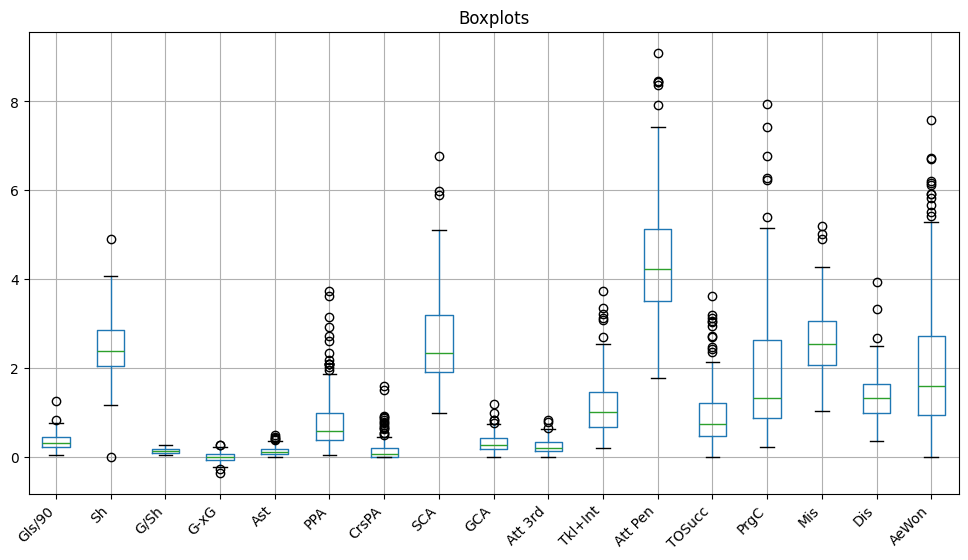

In [ ]:
plt.figure(figsize=(12, 6))

df_8.boxplot()

plt.title("Boxplots")

plt.xticks(rotation=45, ha="right")

plt.show()

In [ ]:
#Standardize data
scaler = StandardScaler()
df_8_standardized = scaler.fit_transform(df_8)

df_8_standardized = pd.DataFrame(df_8_standardized, columns= df_8.columns, index=df_8.index)
df_8_standardized

,Gls/90,Sh,G/Sh,G-xG,Ast,PPA,CrsPA,SCA,GCA,Att 3rd,Tkl+Int,Att Pen,TOSucc,PrgC,Mis,Dis,AeWon
Player,,,,,,,,,,,,,,,,,
Anders Dreyer,-0.832063,0.519088,-1.090689,-0.680758,2.022286,1.845295,1.846858,1.850930,1.109883,-0.695472,-0.643763,0.120380,-0.779098,-0.002956,-0.900138,-1.106254,-1.255390
Andi Zeqiri,0.700386,0.721209,-1.090689,-0.493394,-0.302568,-0.701189,-0.436032,-0.507936,-0.529557,-0.503234,-0.463409,0.142145,-0.668470,-0.387686,0.123460,0.475903,0.213485
Andri Guðjohnsen,-0.321247,-1.424382,1.257684,0.911841,-0.605810,-0.229088,-0.626273,-0.746688,-0.899753,0.778347,-0.433350,-0.401961,-0.530185,-0.498540,0.312018,-0.145659,0.396332
Antoine Bernier,-1.059092,-1.237809,-0.503596,-0.024982,0.303916,0.486216,0.591269,1.258826,0.369491,2.636640,2.091604,-0.068243,0.327182,0.733899,-0.698112,0.174540,-0.828746
Aurélien Scheidler,0.076055,0.083751,0.474893,-0.024982,-0.100407,-0.543822,-0.626273,-0.727588,-1.005523,-1.144025,-0.553586,0.425079,-0.239786,-0.694165,0.029182,-0.315176,2.523457
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Vangelis Pavlidis,2.346349,1.265381,1.453382,0.256065,1.516883,0.171482,-0.474080,0.704922,1.532964,1.547296,-0.403291,1.912301,0.396325,-0.126852,-0.213250,0.042693,-0.432576
Viktor Gyökeres,5.127459,2.571393,1.649080,2.504441,0.910399,0.271625,-0.245791,2.261583,3.595485,-0.310997,-1.004471,3.399522,1.336663,1.535962,0.514044,0.739596,-0.554475
Zé Luís,-0.888820,-0.631446,-1.873480,-0.680758,-0.706890,-0.772720,-0.397984,-0.288285,-0.635327,-0.695472,-0.854176,-0.278630,-0.599327,-0.818061,0.487107,-0.861397,2.346705


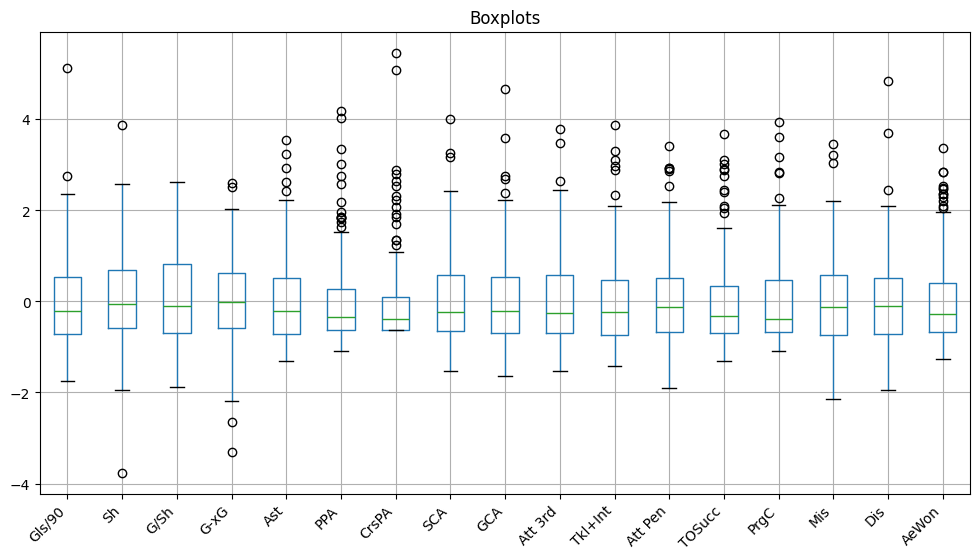

In [ ]:
plt.figure(figsize=(12, 6))

df_8_standardized.boxplot()

plt.title("Boxplots")

plt.xticks(rotation=45, ha="right")

plt.show()

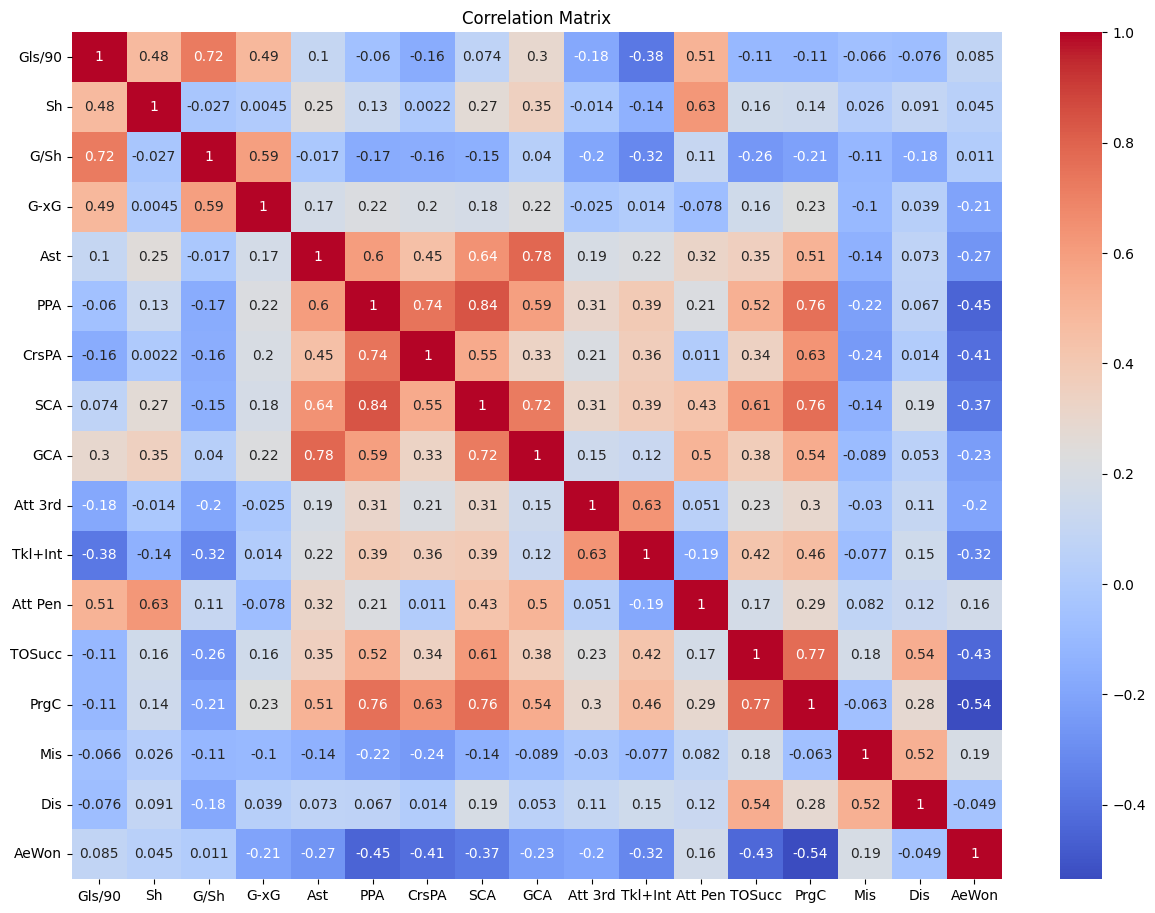

In [ ]:
#Correlation Matrix

corr_matrix = df_8_standardized.corr()

plt.figure(figsize=(15, 11))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

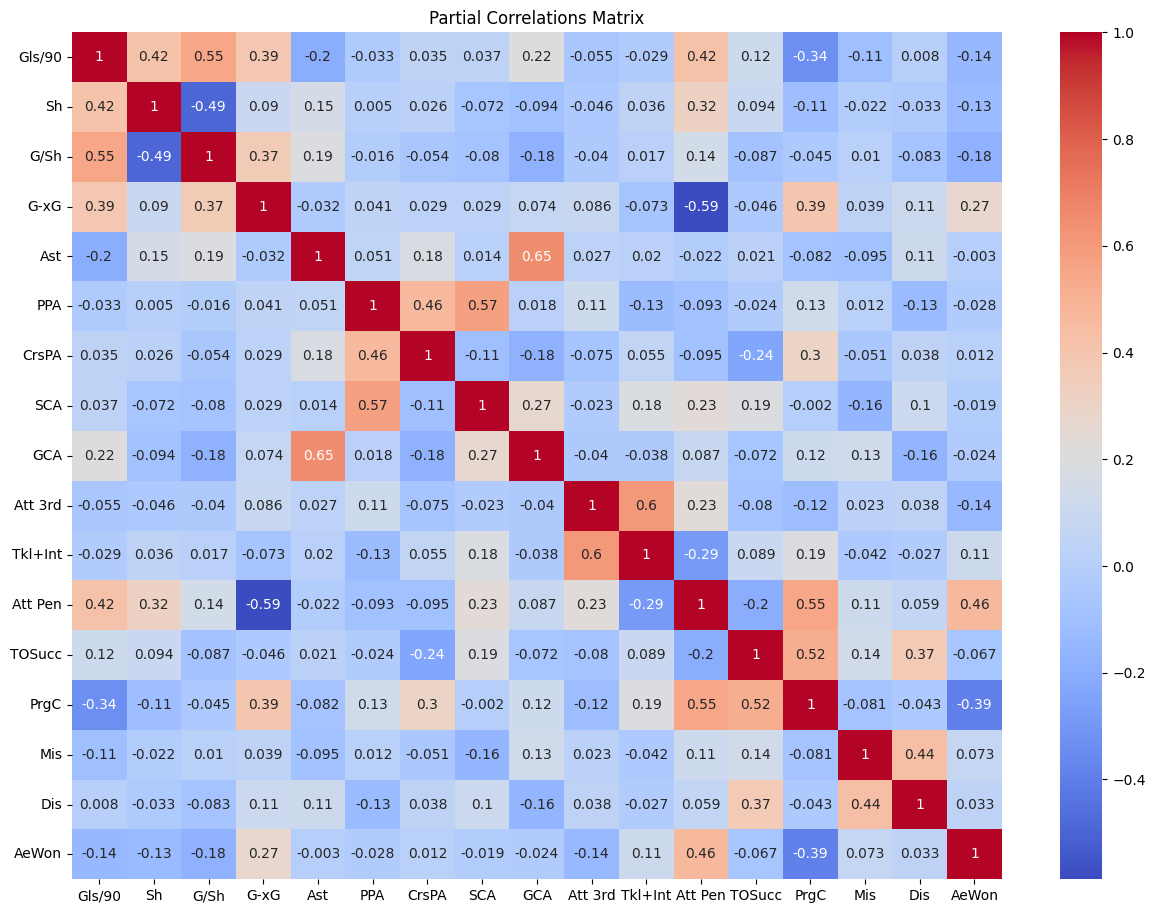

In [ ]:
#Partial correlations

partial_corr_matrix = pd.DataFrame(index=df_8_standardized.columns, columns=df_8_standardized.columns)

for var1 in df_8_standardized.columns:
    for var2 in df_8_standardized.columns:
        if var1 == var2:
            partial_corr_matrix.loc[var1, var2] = 1.0
        else:
            covariates = [col for col in df_8_standardized.columns if col not in [var1, var2]]
            result = pg.partial_corr(data=df_8_standardized, x=var1, y=var2, covar=covariates)
            partial_corr_matrix.loc[var1, var2] = result['r'].values[0]

partial_corr_matrix = partial_corr_matrix.astype(float)


plt.figure(figsize=(15, 11))
sns.heatmap(partial_corr_matrix.round(3), annot=True, cmap='coolwarm')
plt.title('Partial Correlations Matrix')
plt.show()

In [ ]:
#KMO
kmo_all, kmo_model = calculate_kmo(df_8_standardized)

#KMO Overall
print(f"KMO Overall: {kmo_model:.2f}")

kmo_all_series = pd.Series(kmo_all, index=df_8.columns)
print("\nIndividual KMO:")
print(kmo_all_series.round(2))

KMO Overall: 0.73

Individual KMO:
Gls/90     0.60
Sh         0.61
G/Sh       0.60
G-xG       0.51
Ast        0.80
PPA        0.85
CrsPA      0.82
SCA        0.86
GCA        0.79
Att 3rd    0.66
Tkl+Int    0.75
Att Pen    0.50
TOSucc     0.80
PrgC       0.75
Mis        0.64
Dis        0.65
AeWon      0.71
dtype: float64


In [ ]:
#Initialize FA
fa = FactorAnalyzer()
fa.fit(df_8_standardized)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


FactorAnalyzer(rotation_kwargs={})

In [ ]:
#Kaiser Criterion

eigenvalues, _ = fa.get_eigenvalues()
print("Eigenvalues:\n", eigenvalues)

Eigenvalues:
 [5.55250591 2.95894183 2.03207981 1.54309367 1.05071586 0.77515842
 0.61385309 0.47917549 0.47427727 0.37222026 0.29041457 0.24871955
 0.19127694 0.15478334 0.10521264 0.09259032 0.06498102]


In [ ]:
#Pearson Criterion

variance_ratio = eigenvalues / np.sum(eigenvalues)
cumulative_variance = np.cumsum(variance_ratio)
print("Cumulative variance:")
print(cumulative_variance)

Cumulative variance:
[0.32661799 0.5006734  0.6202075  0.71097772 0.77278453 0.81838209
 0.85449109 0.88267789 0.91057655 0.93247186 0.94955507 0.96418563
 0.97543722 0.98454212 0.9907311  0.99617759 1.        ]


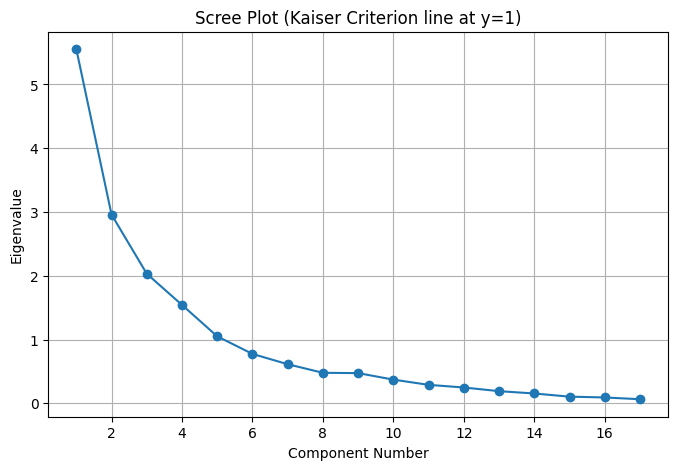

In [ ]:
#Scree Plot

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues)+1), eigenvalues, marker='o')
plt.title('Scree Plot (Kaiser Criterion line at y=1)')
plt.xlabel('Component Number')
plt.ylabel('Eigenvalue')
plt.grid(True)
plt.show()

In [ ]:
#Perform FA with the number of factors you want to retain

n_factors = 3
fa = FactorAnalyzer(n_factors, rotation= None, method="principal")
fa.fit(df_8_standardized)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


FactorAnalyzer(method='principal', rotation=None, rotation_kwargs={})

In [ ]:
#Loadings

loadings = fa.loadings_

loadings_df = pd.DataFrame(loadings, index=df_8_standardized.columns, columns=["F1", "F2", "F3"])
loadings_df

,F1,F2,F3
Gls/90,-0.008689,0.916244,-0.051955
Sh,0.254350,0.550038,0.426151
G/Sh,-0.191553,0.680531,-0.414883
G-xG,0.238417,0.428201,-0.449309
Ast,0.724751,0.236319,-0.041661
PPA,0.880617,-0.028267,-0.178771
CrsPA,0.692079,-0.165849,-0.320724
SCA,0.904844,0.114183,0.046909
GCA,0.726624,0.421038,0.054348
Att 3rd,0.416788,-0.333381,0.005143


In [ ]:
#Varimax Rotation

rotator = Rotator(method= "Varimax")
rotated_loadings = rotator.fit_transform(loadings)

rotated_df = pd.DataFrame(rotated_loadings, index=df_8_standardized.columns, columns=["F1", "F2", "F3"])

print("Rotated Loadings (Varimax):")
rotated_df

Rotated Loadings (Varimax):


,F1,F2,F3
Gls/90,-0.196960,0.743314,-0.500968
Sh,0.049141,0.731235,0.108269
G/Sh,-0.256681,0.325444,-0.707208
G-xG,0.216698,0.216015,-0.590302
Ast,0.652080,0.379185,-0.117718
PPA,0.883359,0.135897,-0.097231
CrsPA,0.757484,-0.097983,-0.161123
SCA,0.835492,0.367578,0.028638
GCA,0.596811,0.579719,-0.126297
Att 3rd,0.471158,-0.162717,0.190827


In [ ]:
#Communalities

communalities = fa.get_communalities()
print("\nCommunalities:\n", communalities)


Communalities:
 [0.84227736 0.54884141 0.67194273 0.44207723 0.58284657 0.8082451
 0.6093427  0.83398096 0.70820931 0.28488131 0.58107261 0.72996564
 0.65227506 0.81420206 0.5009032  0.48583047 0.44663383]


In [ ]:
#RMSR

reconstructed_corr = np.dot(loadings, loadings.T)

residuals = corr_matrix.values - reconstructed_corr

mask = ~np.eye(residuals.shape[0], dtype=bool)

rmsr = np.sqrt(np.mean(residuals[mask]**2))

print(f"RMSR: {rmsr:.3f}")

RMSR: 0.094


In [ ]:
#Interpretation - get factor scores

fa = FactorAnalyzer(n_factors=3, rotation="varimax", method="principal")
fa.fit(df_8_standardized)

factor_scores = fa.transform(df_8_standardized)
factor_scores_df = pd.DataFrame(factor_scores, columns=["Playmaking & Workrate", "Pure Finishing Threat", "Error Proneness"], index=df_8_standardized.index)
factor_scores_df

/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,Playmaking & Workrate,Pure Finishing Threat,Error Proneness
Player,,,
Anders Dreyer,1.248796,-0.052545,-0.689094
Andi Zeqiri,-0.678634,0.329606,0.550940
Andri Guðjohnsen,-0.530579,-0.629831,-0.563519
Antoine Bernier,1.422556,-1.141845,0.208059
Aurélien Scheidler,-1.114834,0.395523,0.083213
...,...,...,...
Vangelis Pavlidis,0.252294,2.038370,-0.658851
Viktor Gyökeres,0.554912,4.504145,-1.108324
Zé Luís,-0.975015,-0.484249,0.892914


In [ ]:
#Check mean and variances of each factor

means = factor_scores_df.mean()
variances = factor_scores_df.var()

summary = pd.DataFrame({'Mean': means, 'Variance': variances})
print(summary.round(0))

                       Mean  Variance
Playmaking & Workrate   0.0       1.0
Pure Finishing Threat  -0.0       1.0
Error Proneness         0.0       1.0


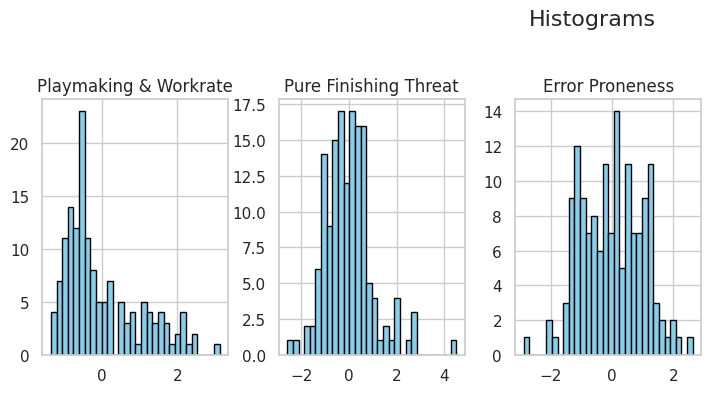

In [ ]:
#Plot histograms

sns.set(style="whitegrid")
factor_scores_df.hist(bins=30, figsize=(12, 4), layout=(1, 5), color='skyblue', edgecolor='black')
plt.suptitle('Histograms', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

###OUTLIERS

In [ ]:
df_analysis = factor_scores_df.copy()

# --- PASSO 1: DETETAR E SEPARAR OUTLIERS (Método IQR) ---
Q1 = df_analysis.quantile(0.25)
Q3 = df_analysis.quantile(0.75)
IQR = Q3 - Q1

# Definição de Outlier: 1.5x o IQR (Podes aumentar para 2.0 se quiseres ser mais conservador)
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Máscara: Quem é outlier em PELO MENOS UM fator?
is_outlier = ((df_analysis < limite_inferior) | (df_analysis > limite_superior)).any(axis=1)

# Separar os datasets
df_outliers = df_analysis[is_outlier].copy()
df_normais = df_analysis[~is_outlier].copy()

print(f"Total Jogadores: {len(df_analysis)}")
print(f"Jogadores Normais: {len(df_normais)}")
print(f"Outliers (Aliens): {len(df_outliers)}")
print("Lista de Aliens:", df_outliers.index.tolist())

Total Jogadores: 150
Jogadores Normais: 144
Outliers (Aliens): 6
Lista de Aliens: ['Tolu Arokodare', 'Estêvão Willian', 'Ryan Hedges', 'Noa Lang', 'Wout Weghorst', 'Viktor Gyökeres']


In [ ]:
# 1. Ordenar: Põe os "Melhores" (Aliens Positivos) no topo para destaque
# Ordena por um dos teus fatores principais (ex: Finishing ou Playmaking)
# (Podes mudar 'Pure Finishing Threat' para o fator que preferires)
df_outliers_sorted = df_outliers.sort_values(by='Pure Finishing Threat', ascending=False)

print()

# 2. Apresentar a Tabela
# O comando display() deixa a tabela bonita no Google Colab/Jupyter
try:
    # Tenta usar o estilo visual (cores ajudam a ver onde o valor é extremo)
    display(df_outliers_sorted.style.background_gradient(cmap='coolwarm', axis=0))
except:
    # Fallback se não der para usar estilos
    print(df_outliers_sorted)

# 3. (Opcional) Guardar numa lista para usares no texto do report
threshold_alien = 1.5

aliens_mask = (df_outliers['Playmaking & Workrate'] > threshold_alien) | \
              (df_outliers['Pure Finishing Threat'] > threshold_alien)

# Separar os nomes
lista_aliens = df_outliers[aliens_mask].index.tolist()
lista_negativos = df_outliers[~aliens_mask].index.tolist()

print("-" * 30)
print(f"👽 Aliens ({len(lista_aliens)}): {', '.join(lista_aliens)}")
print(f"🔻 Negative Outliers ({len(lista_negativos)}): {', '.join(lista_negativos)}")
print("-" * 30)

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness
Player,,,
Viktor Gyökeres,0.554912,4.504145,-1.108324
Tolu Arokodare,-0.932076,2.759065,1.141685
Wout Weghorst,-0.616704,2.711414,-1.550719
Noa Lang,3.132365,2.686757,-1.490330
Estêvão Willian,2.220318,2.524382,0.769495
Ryan Hedges,1.076364,-2.583520,0.488313


------------------------------
👽 Aliens (5): Tolu Arokodare, Estêvão Willian, Noa Lang, Wout Weghorst, Viktor Gyökeres
🔻 Negative Outliers (1): Ryan Hedges
------------------------------


### Clusters

#####Hierarchical Clustering

In [ ]:
factor_scores_df = factor_scores_df.drop(df_outliers.index, errors='ignore')
factor_scores_df

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness
Player,,,
Anders Dreyer,1.248796,-0.052545,-0.689094
Andi Zeqiri,-0.678634,0.329606,0.550940
Andri Guðjohnsen,-0.530579,-0.629831,-0.563519
Antoine Bernier,1.422556,-1.141845,0.208059
Aurélien Scheidler,-1.114834,0.395523,0.083213
...,...,...,...
Tomané,-0.954359,-0.745950,0.849707
Vangelis Pavlidis,0.252294,2.038370,-0.658851
Zé Luís,-0.975015,-0.484249,0.892914


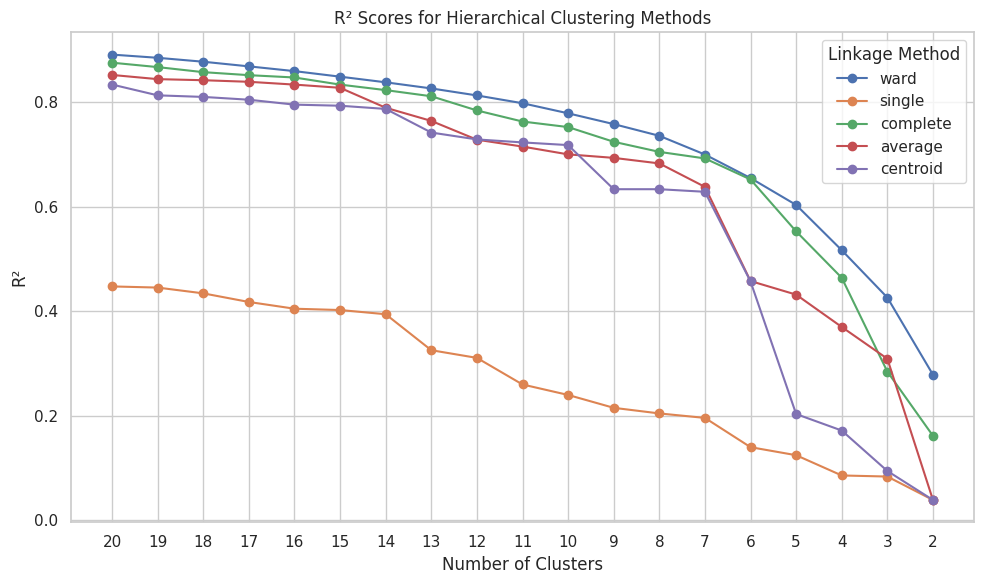

In [ ]:
#Choose the best hierarchical method

methods = ['ward', 'single', 'complete', 'average', 'centroid']
max_clusters = 20

grand_centroid = factor_scores_df.mean().values
tss = ((factor_scores_df.values - grand_centroid) ** 2).sum()

results = []

for method in methods:
    Z = linkage(factor_scores_df, method=method)

    for k in range(2, max_clusters + 1):
        labels = fcluster(Z, k, criterion='maxclust')


        wss = 0
        for cluster_id in np.unique(labels):
            cluster_points = factor_scores_df.values[labels == cluster_id]
            centroid = cluster_points.mean(axis=0)
            wss += ((cluster_points - centroid) ** 2).sum()

        r_squared = 1 - wss / tss
        results.append({'method': method, 'clusters': k, 'R_squared': r_squared})

df_r2 = pd.DataFrame(results, columns=['method', 'clusters', 'R_squared'])
df_pivot = df_r2.pivot(index='clusters', columns='method', values='R_squared')

#Plot
plt.figure(figsize=(10, 6))
for method in methods:
    plt.plot(df_pivot.index, df_pivot[method], marker='o', label=method)

plt.title('R² Scores for Hierarchical Clustering Methods')
plt.xlabel('Number of Clusters')
plt.ylabel('R²')
plt.xticks(df_pivot.index)
plt.legend(title='Linkage Method')
plt.grid(True)
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

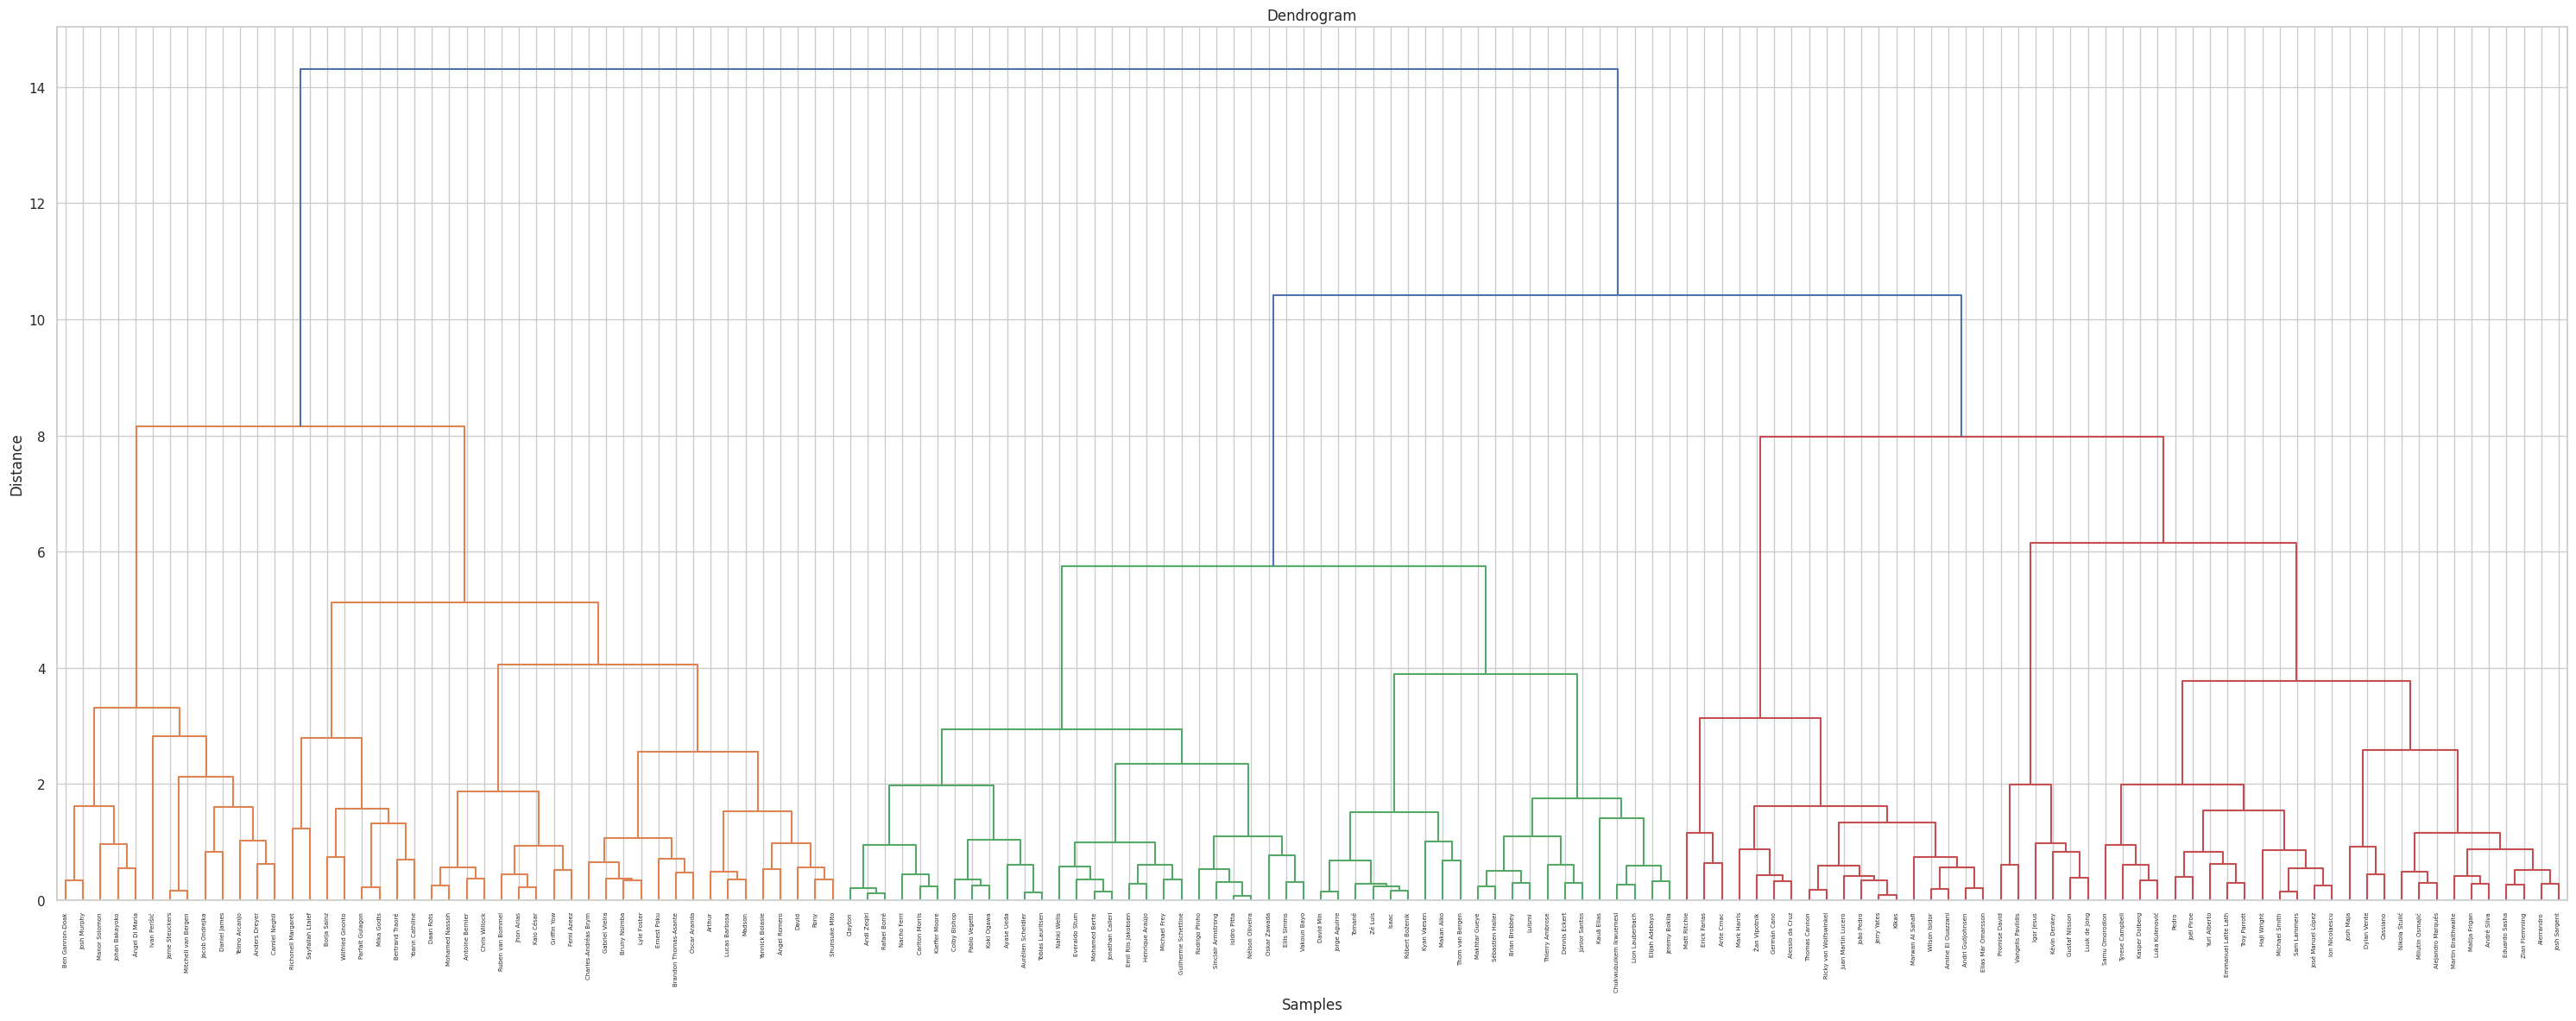

In [ ]:
#Dendrogram

Z = linkage(factor_scores_df, method='ward')

plt.figure(figsize=(30, 12))
dendrogram(Z, labels=factor_scores_df.index.tolist(), leaf_rotation=90)
plt.title("Dendrogram")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

In [ ]:
#Choose number of Clusters

n_clusters = 5

hierarchical_labels = fcluster(Z, n_clusters, criterion="maxclust")

In [ ]:
#Assign Cluster labels

df_8_original = factor_scores_df.copy()
df_8_original['Cluster'] = hierarchical_labels
df_8_original

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness,Cluster
Player,,,,
Anders Dreyer,1.248796,-0.052545,-0.689094,1
Andi Zeqiri,-0.678634,0.329606,0.550940,3
Andri Guðjohnsen,-0.530579,-0.629831,-0.563519,4
Antoine Bernier,1.422556,-1.141845,0.208059,2
Aurélien Scheidler,-1.114834,0.395523,0.083213,3
...,...,...,...,...
Tomané,-0.954359,-0.745950,0.849707,3
Vangelis Pavlidis,0.252294,2.038370,-0.658851,5
Zé Luís,-0.975015,-0.484249,0.892914,3


In [ ]:
#Calculate cluster means

initial_seeds = df_8_original.groupby("Cluster").mean()
initial_seeds

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness
Cluster,,,
1,1.775903,-0.058271,-0.923493
2,0.928378,-0.366136,0.746827
3,-0.685376,-0.070285,0.651152
4,-0.484141,-1.005855,-0.828346
5,-0.503558,0.646991,-0.802674


#####Non-hierarchical Clustering

In [ ]:
df_8_original = df_8_original.drop(columns=["Cluster"])
df_8_original

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness
Player,,,
Anders Dreyer,1.248796,-0.052545,-0.689094
Andi Zeqiri,-0.678634,0.329606,0.550940
Andri Guðjohnsen,-0.530579,-0.629831,-0.563519
Antoine Bernier,1.422556,-1.141845,0.208059
Aurélien Scheidler,-1.114834,0.395523,0.083213
...,...,...,...
Tomané,-0.954359,-0.745950,0.849707
Vangelis Pavlidis,0.252294,2.038370,-0.658851
Zé Luís,-0.975015,-0.484249,0.892914


In [ ]:
#Perform K-means

kmeans = KMeans(n_clusters = n_clusters, init=initial_seeds.values)
kmeans.fit(df_8_original)

KMeans(init=array([[ 1.77590331, -0.05827065, -0.92349325],
       [ 0.9283778 , -0.36613619,  0.74682708],
       [-0.68537602, -0.07028461,  0.65115211],
       [-0.48414066, -1.00585536, -0.8283459 ],
       [-0.50355849,  0.64699061, -0.80267425]]),
       n_clusters=5)

In [ ]:
#Assign Cluster Labels

df_8_original['kmeans_cluster'] = kmeans.labels_
df_8_original

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness,kmeans_cluster
Player,,,,
Anders Dreyer,1.248796,-0.052545,-0.689094,0
Andi Zeqiri,-0.678634,0.329606,0.550940,2
Andri Guðjohnsen,-0.530579,-0.629831,-0.563519,3
Antoine Bernier,1.422556,-1.141845,0.208059,1
Aurélien Scheidler,-1.114834,0.395523,0.083213,4
...,...,...,...,...
Tomané,-0.954359,-0.745950,0.849707,2
Vangelis Pavlidis,0.252294,2.038370,-0.658851,4
Zé Luís,-0.975015,-0.484249,0.892914,2


In [ ]:
#R2

X = df_8_original.drop(columns=['kmeans_cluster']).values
X_pred = kmeans.cluster_centers_[kmeans.labels_]

r2 = explained_variance_score(X, X_pred)
print(f"Overall R²: {r2:.3f}")

Overall R²: 0.629


In [ ]:
#Compute R2 of each factor

X = df_8_original.drop(columns=['kmeans_cluster']).copy()
labels = kmeans.labels_
centroids = kmeans.cluster_centers_

r2_per_factor = {}

for i, col in enumerate(X.columns):
    y_true = X[col].values
    y_pred = centroids[labels, i]

    r2 = explained_variance_score(y_true, y_pred)
    r2_per_factor[col] = round(r2, 4)

print("R² per Factor:")
for factor, r2 in r2_per_factor.items():
    print(f"  {factor}: {r2}")

R² per Factor:
  Playmaking & Workrate: 0.7936
  Pure Finishing Threat: 0.406
  Error Proneness: 0.6872


In [ ]:
#Group by cluster and compute means

cluster_means = df_8_original.groupby("kmeans_cluster").mean()
cluster_means

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness
kmeans_cluster,,,
0,1.775903,-0.058271,-0.923493
1,1.058439,-0.382854,0.695754
2,-0.582952,-0.088554,1.020545
3,-0.546193,-0.705309,-0.899289
4,-0.561450,0.751822,-0.476646


### Interpretation

####Data Prep

In [ ]:
aliens_cluster_labels = kmeans.predict(df_outliers.drop(columns=['Cluster', 'Type'], errors='ignore'))

# Atribuir os labels ao dataframe dos aliens
df_outliers['Cluster'] = aliens_cluster_labels

# --- PASSO 2: CRIAR A COLUNA 'TYPE' (Para os gráficos) ---
# Isto é crucial para saberes quem é quem no desenho
df_normais['Type'] = 'Normal'
df_outliers['Type'] = 'Alien'

# --- PASSO 3: JUNTAR TUDO (O Dataset Final) ---
df_final_completo = pd.concat([df_normais, df_outliers])

# (Opcional) Ordenar para ficar bonito
df_final_completo = df_final_completo.sort_index()

print("--- Reintegração Concluída ---")
print(f"Total Jogadores: {len(df_final_completo)}")
print(f"Aliens Reintegrados: {len(df_outliers)}")
print(df_outliers[['Cluster']]) # Mostra onde é que os Aliens caíram

--- Reintegração Concluída ---
Total Jogadores: 150
Aliens Reintegrados: 6
                 Cluster
Player                  
Tolu Arokodare         4
Estêvão Willian        0
Ryan Hedges            1
Noa Lang               0
Wout Weghorst          4
Viktor Gyökeres        4


In [ ]:
# 1. Garantir que os clusters estão atribuídos nos dataframes originais
df_normais['Cluster'] = kmeans.labels_
df_outliers['Cluster'] = aliens_cluster_labels

# 2. Garantir que o Tipo está atribuído
df_normais['Type'] = 'Normal'
df_outliers['Type'] = 'Alien'

# 3. Juntar (Concatenar)
df_final_completo = pd.concat([df_normais, df_outliers])

# 4. Preparar o dataset para os gráficos (df_plot)
df_plot = df_final_completo.copy().reset_index()

# Renomear a coluna do índice para 'Player'
# (Verifica qual o nome que aparece. Se o index não tinha nome, costuma ficar 'index')
if 'index' in df_plot.columns:
    df_plot = df_plot.rename(columns={'index': 'Player'})
else:
    # Se o nome for outro (ex: 'Equipa' ou vazio), renomeia a primeira coluna
    df_plot.rename(columns={df_plot.columns[0]: 'Player'}, inplace=True)

# 5. LIMPEZA FINAL CRUCIAL (O que resolve o "nan")
# Converter Cluster para inteiro e depois para string (remove "1.0")
# E preencher possíveis vazios
df_plot['Cluster'] = df_plot['Cluster'].fillna(-1).astype(int).astype(str)
df_plot['Type'] = df_plot['Type'].fillna('Normal')

print("Verificação de Clusters (Não deve haver 'nan'):")
print(df_plot['Cluster'].unique())

Verificação de Clusters (Não deve haver 'nan'):
['0' '2' '3' '1' '4']


In [ ]:
# Criar uma cópia para gráficos
df_plot = df_final_completo.copy()

# Reset ao index para o "Nome" passar a ser uma coluna
df_plot = df_plot.reset_index()
df_plot = df_plot.rename(columns={'index': 'Player'}) # O nome da coluna do index passa a ser 'Player'

# Garantir que o Cluster é texto (para cores discretas) e Type está preenchido
df_plot['Cluster'] = df_plot['Cluster'].astype(str)
df_plot['Type'] = df_plot['Type'].fillna('Normal')

print("Dados prontos para plotar!")
print(df_plot.head())

Dados prontos para plotar!
               Player  Playmaking & Workrate  Pure Finishing Threat  \
0       Anders Dreyer               1.248796              -0.052545   
1         Andi Zeqiri              -0.678634               0.329606   
2    Andri Guðjohnsen              -0.530579              -0.629831   
3     Antoine Bernier               1.422556              -1.141845   
4  Aurélien Scheidler              -1.114834               0.395523   

   Error Proneness    Type Cluster  
0        -0.689094  Normal       0  
1         0.550940  Normal       2  
2        -0.563519  Normal       3  
3         0.208059  Normal       1  
4         0.083213  Normal       4  


####Gráficos Com os Aliens

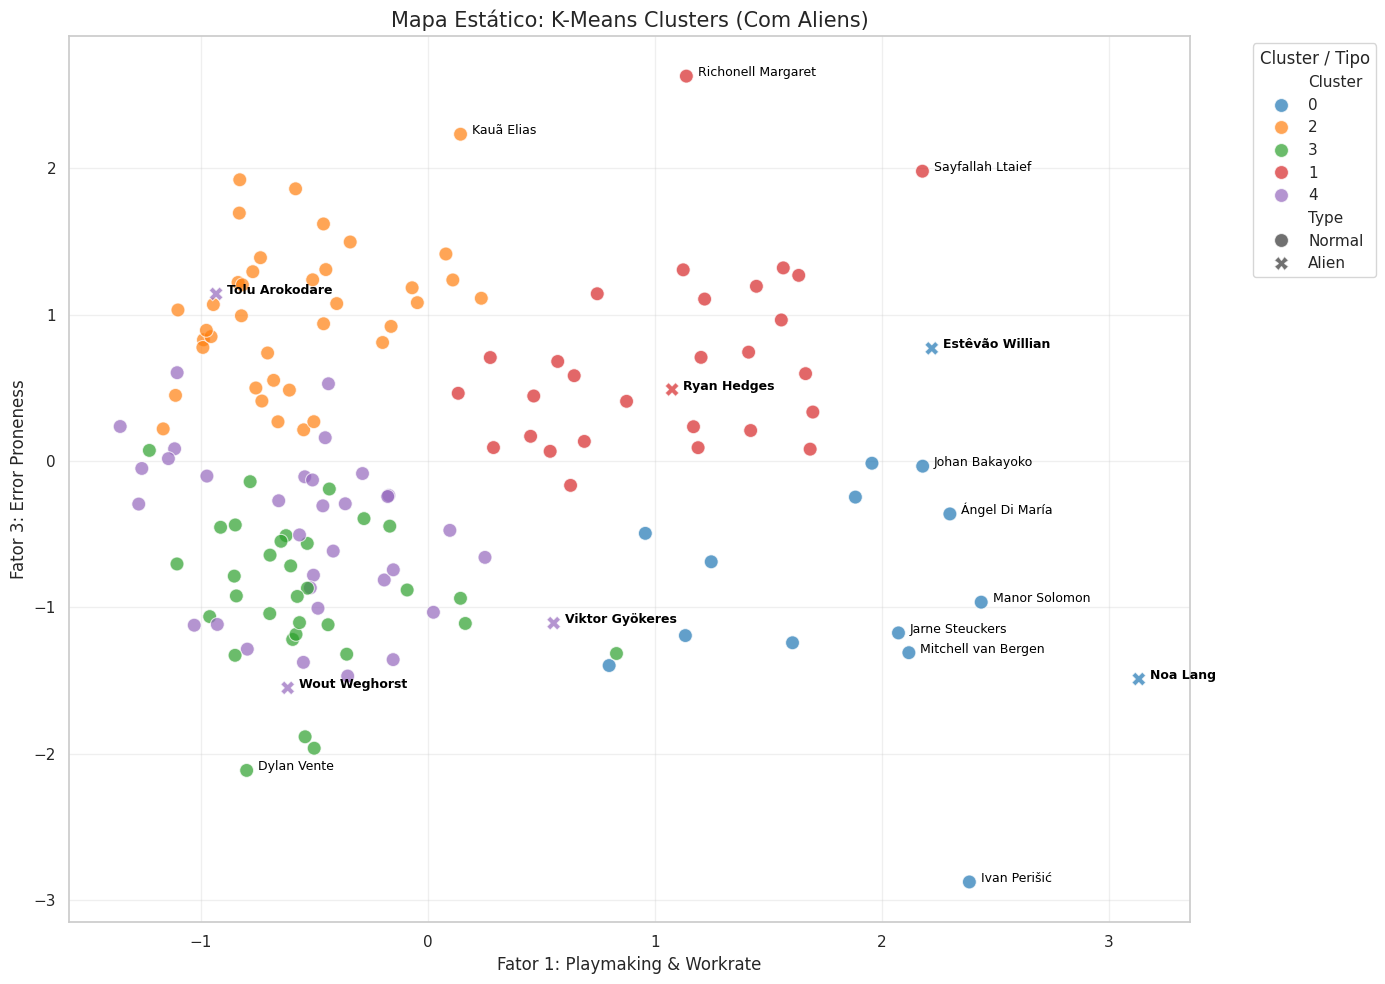

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

# Usar Seaborn é mais fácil que o loop manual do matplotlib para cores/estilos
sns.scatterplot(data=df_plot,
                x='Playmaking & Workrate',
                y='Error Proneness', # O eixo que pediste
                hue='Cluster',       # Cor por Cluster
                style='Type',        # Forma por Tipo (Alien vs Normal)
                palette='tab10',     # A paleta que querias
                s=100,               # Tamanho dos pontos
                alpha=0.7)

# Adicionar nomes (Filtro inteligente para não encavalitar tudo)
for i in range(df_plot.shape[0]):
    # Só mete nome se for Alien OU se for "extremo" nos eixos
    if (df_plot.iloc[i]['Type'] == 'Alien') or \
       (abs(df_plot.iloc[i]['Playmaking & Workrate']) > 2) or \
       (abs(df_plot.iloc[i]['Error Proneness']) > 2):

        plt.text(df_plot.iloc[i]['Playmaking & Workrate']+0.05,
                 df_plot.iloc[i]['Error Proneness'],
                 df_plot.iloc[i]['Player'],
                 fontsize=9,
                 color='black',
                 weight='bold' if df_plot.iloc[i]['Type'] == 'Alien' else 'normal')

plt.xlabel('Fator 1: Playmaking & Workrate')
plt.ylabel('Fator 3: Error Proneness')
plt.title('Mapa Estático: K-Means Clusters (Com Aliens)', fontsize=15)
plt.legend(title='Cluster / Tipo', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

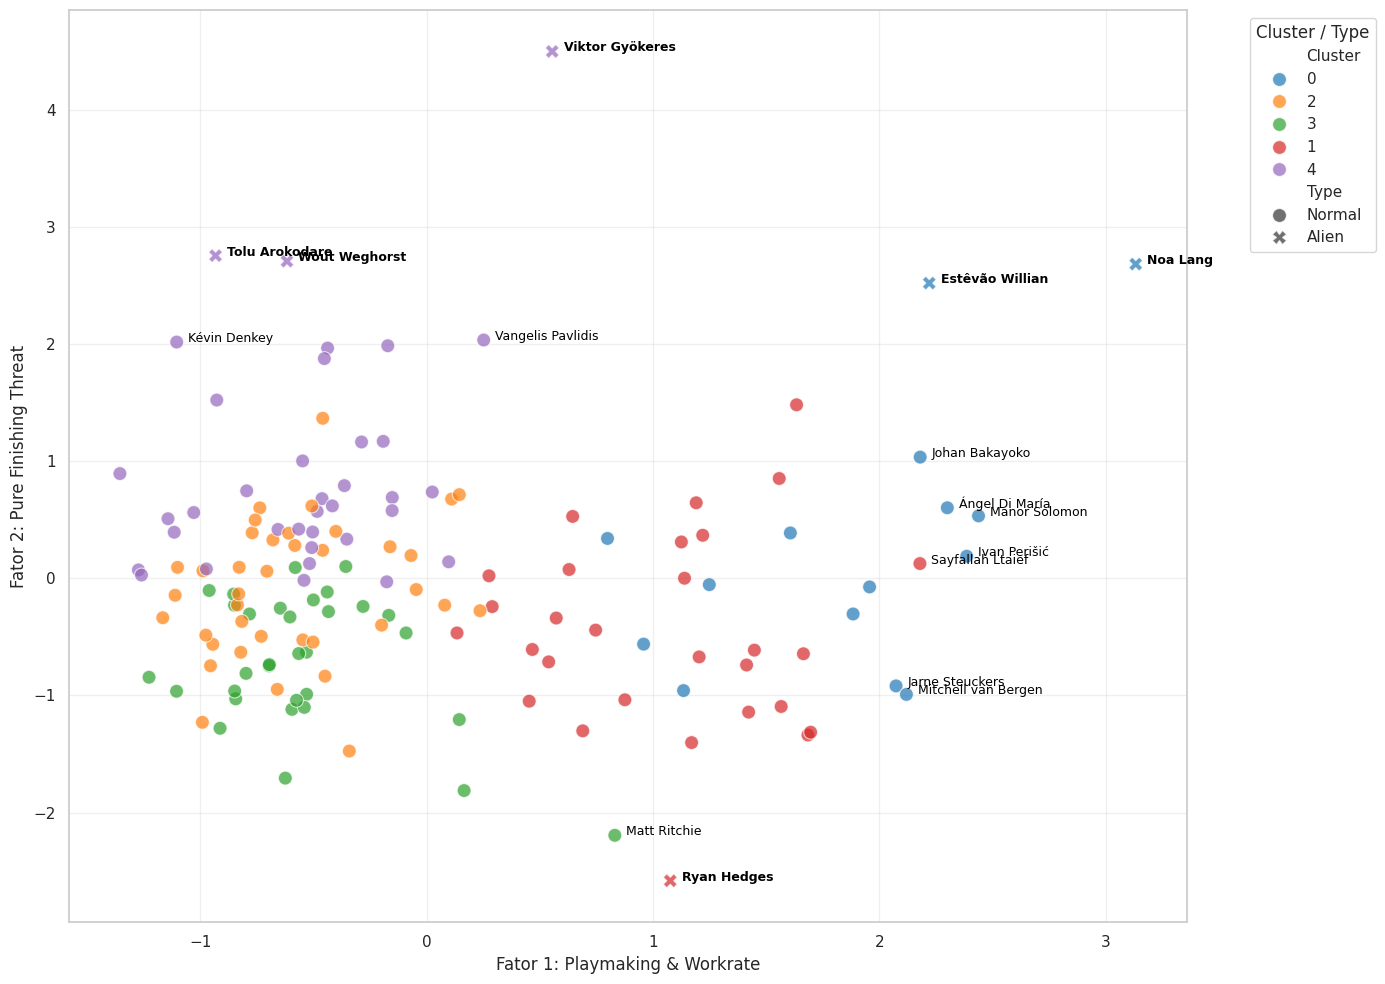

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

# Usar Seaborn é mais fácil que o loop manual do matplotlib para cores/estilos
sns.scatterplot(data=df_plot,
                x='Playmaking & Workrate',
                y='Pure Finishing Threat', # O eixo que pediste
                hue='Cluster',       # Cor por Cluster
                style='Type',        # Forma por Tipo (Alien vs Normal)
                palette='tab10',     # A paleta que querias
                s=100,               # Tamanho dos pontos
                alpha=0.7)

# Adicionar nomes (Filtro inteligente para não encavalitar tudo)
for i in range(df_plot.shape[0]):
    # Só mete nome se for Alien OU se for "extremo" nos eixos
    if (df_plot.iloc[i]['Type'] == 'Alien') or \
       (abs(df_plot.iloc[i]['Playmaking & Workrate']) > 2) or \
       (abs(df_plot.iloc[i]['Pure Finishing Threat']) > 2):

        plt.text(df_plot.iloc[i]['Playmaking & Workrate']+0.05,
                 df_plot.iloc[i]['Pure Finishing Threat'],
                 df_plot.iloc[i]['Player'],
                 fontsize=9,
                 color='black',
                 weight='bold' if df_plot.iloc[i]['Type'] == 'Alien' else 'normal')

plt.xlabel('Fator 1: Playmaking & Workrate')
plt.ylabel('Fator 2: Pure Finishing Threat')
plt.legend(title='Cluster / Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

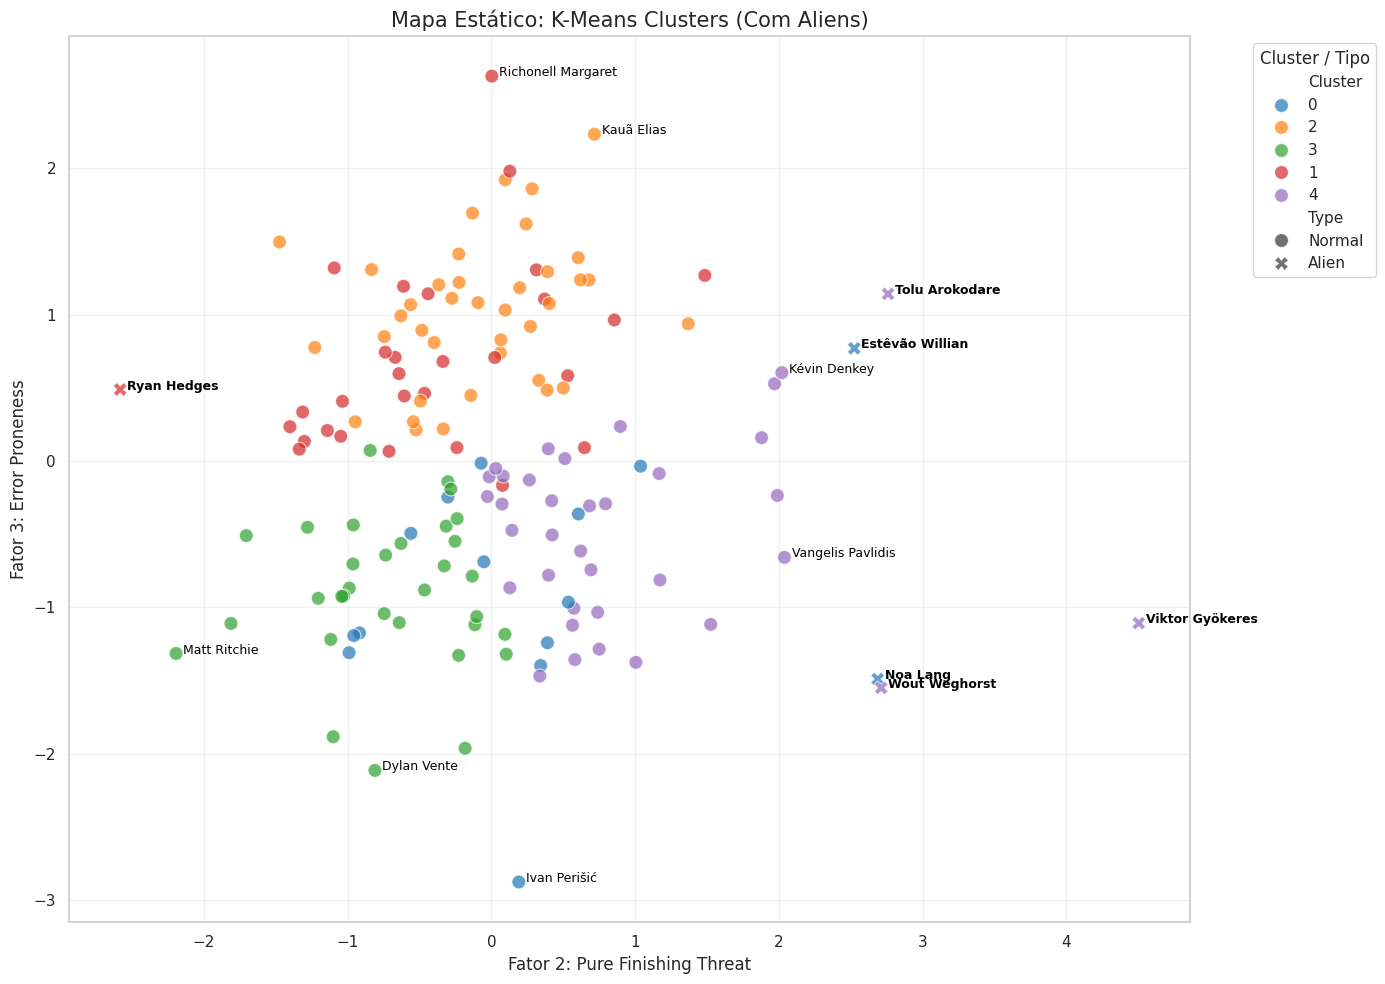

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

# Usar Seaborn é mais fácil que o loop manual do matplotlib para cores/estilos
sns.scatterplot(data=df_plot,
                x='Pure Finishing Threat',
                y='Error Proneness', # O eixo que pediste
                hue='Cluster',       # Cor por Cluster
                style='Type',        # Forma por Tipo (Alien vs Normal)
                palette='tab10',     # A paleta que querias
                s=100,               # Tamanho dos pontos
                alpha=0.7)

# Adicionar nomes (Filtro inteligente para não encavalitar tudo)
for i in range(df_plot.shape[0]):
    # Só mete nome se for Alien OU se for "extremo" nos eixos
    if (df_plot.iloc[i]['Type'] == 'Alien') or \
       (abs(df_plot.iloc[i]['Pure Finishing Threat']) > 2) or \
       (abs(df_plot.iloc[i]['Error Proneness']) > 2):

        plt.text(df_plot.iloc[i]['Pure Finishing Threat']+0.05,
                 df_plot.iloc[i]['Error Proneness'],
                 df_plot.iloc[i]['Player'],
                 fontsize=9,
                 color='black',
                 weight='bold' if df_plot.iloc[i]['Type'] == 'Alien' else 'normal')

plt.xlabel('Fator 2: Pure Finishing Threat')
plt.ylabel('Fator 3: Error Proneness')
plt.title('Mapa Estático: K-Means Clusters (Com Aliens)', fontsize=15)
plt.legend(title='Cluster / Tipo', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px

# 1. Criar uma coluna numérica para o tamanho (Truque para substituir o size_map)
# Normais = 10, Aliens = 25 (para se destacarem bem)
df_plot['Marker_Size'] = df_plot['Type'].map({'Normal': 10, 'Alien': 25})

# 2. Criar o Gráfico
fig = px.scatter(df_plot,
                 x='Playmaking & Workrate',
                 y='Pure Finishing Threat',
                 color='Cluster',

                 # SÍMBOLOS (Isto funciona)
                 symbol='Type',
                 symbol_map={'Normal': 'circle', 'Alien': 'star'},

                 # TAMANHO (A forma corrigida)
                 size='Marker_Size',
                 size_max=20, # Define o tamanho máximo das bolhas no ecrã

                 hover_name='Player',
                 hover_data=['Type'],
                 title='<b>Mapa Interativo dos Perfis (Passa o rato!)</b>',
                 template='plotly_dark',
                 width=1100,
                 height=750)

# Design
fig.update_traces(marker=dict(line=dict(width=1, color='White')))
fig.update_layout(
    legend_title_text='Perfil Tático',
    xaxis_title='Fator 1: Playmaking & Workrate',
    yaxis_title='Fator 2: Pure Finishing Threat'
)

fig.show()

In [ ]:
# 1. Criar uma coluna numérica para o tamanho (Truque para substituir o size_map)
# Normais = 10, Aliens = 25 (para se destacarem bem)
df_plot['Marker_Size'] = df_plot['Type'].map({'Normal': 10, 'Alien': 25})

# 2. Criar o Gráfico
fig = px.scatter(df_plot,
                 x='Playmaking & Workrate',
                 y='Error Proneness',
                 color='Cluster',

                 # SÍMBOLOS (Isto funciona)
                 symbol='Type',
                 symbol_map={'Normal': 'circle', 'Alien': 'star'},

                 # TAMANHO (A forma corrigida)
                 size='Marker_Size',
                 size_max=20, # Define o tamanho máximo das bolhas no ecrã

                 hover_name='Player',
                 hover_data=['Type'],
                 title='<b>Mapa Interativo dos Perfis (Passa o rato!)</b>',
                 template='plotly_dark',
                 width=1100,
                 height=750)

# Design
fig.update_traces(marker=dict(line=dict(width=1, color='White')))
fig.update_layout(
    legend_title_text='Perfil Tático',
    xaxis_title='Fator 1: Playmaking & Workrate',
    yaxis_title='Fator 3: Error Proneness'
)

fig.show()

In [ ]:
# 1. Criar uma coluna numérica para o tamanho (Truque para substituir o size_map)
# Normais = 10, Aliens = 25 (para se destacarem bem)
df_plot['Marker_Size'] = df_plot['Type'].map({'Normal': 10, 'Alien': 25})

# 2. Criar o Gráfico
fig = px.scatter(df_plot,
                 x='Pure Finishing Threat',
                 y='Error Proneness',
                 color='Cluster',

                 # SÍMBOLOS (Isto funciona)
                 symbol='Type',
                 symbol_map={'Normal': 'circle', 'Alien': 'star'},

                 # TAMANHO (A forma corrigida)
                 size='Marker_Size',
                 size_max=20, # Define o tamanho máximo das bolhas no ecrã

                 hover_name='Player',
                 hover_data=['Type'],
                 title='<b>Mapa Interativo dos Perfis (Passa o rato!)</b>',
                 template='plotly_dark',
                 width=1100,
                 height=750)

# Design
fig.update_traces(marker=dict(line=dict(width=1, color='White')))
fig.update_layout(
    legend_title_text='Perfil Tático',
    xaxis_title='Fator 2: Pure Finishing Threat',
    yaxis_title='Fator 3: Error Proneness'
)

fig.show()

####Gráficos sem os aliens

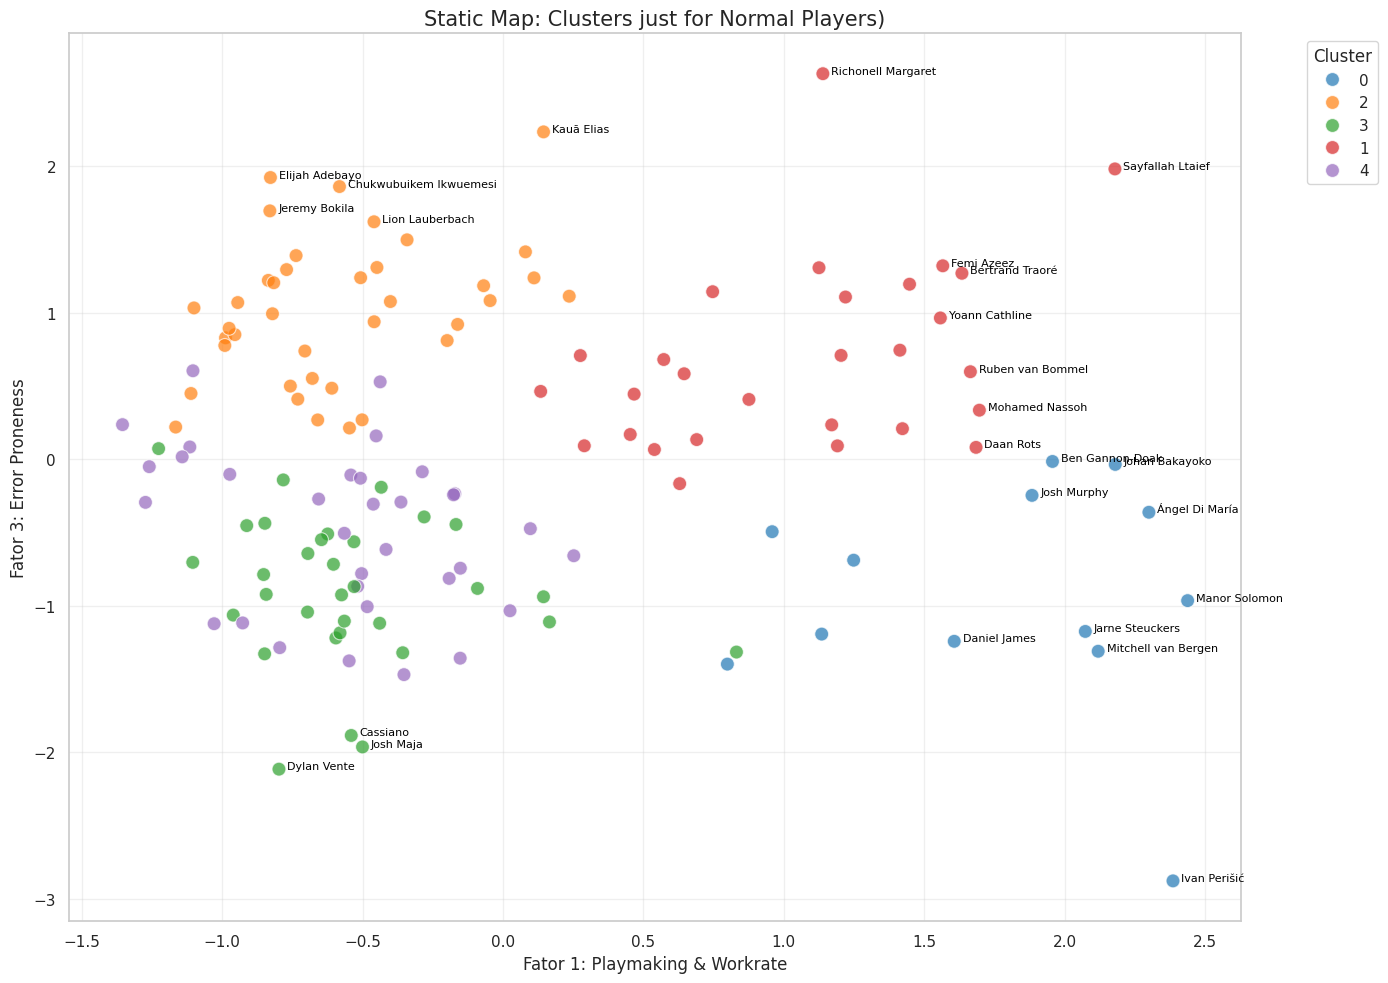

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

# --- FILTRAR SÓ OS NORMAIS ---
df_zoom = df_plot[df_plot['Type'] == 'Normal'].copy()

# Usar Seaborn
sns.scatterplot(data=df_zoom,
                x='Playmaking & Workrate',
                y='Error Proneness', # O eixo que pediste
                hue='Cluster',       # Cor por Cluster
                # style='Type',      # Removemos o style porque agora são todos 'Normal'
                palette='tab10',
                s=100,
                alpha=0.7)

# Adicionar nomes (Filtro ajustado para mostrar os destaques "humanos")
for i in range(df_zoom.shape[0]):
    # Mostra nome se for extremo DENTRO da escala normal (> 1.5 ou < -1.5)
    if (abs(df_zoom.iloc[i]['Playmaking & Workrate']) > 1.5) or \
       (abs(df_zoom.iloc[i]['Error Proneness']) > 1.5):

        plt.text(df_zoom.iloc[i]['Playmaking & Workrate']+0.03,
                 df_zoom.iloc[i]['Error Proneness'],
                 df_zoom.iloc[i]['Player'],
                 fontsize=8,
                 color='black')

plt.xlabel('Fator 1: Playmaking & Workrate')
plt.ylabel('Fator 3: Error Proneness')
plt.title('Static Map: Clusters just for Normal Players)', fontsize=15)
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

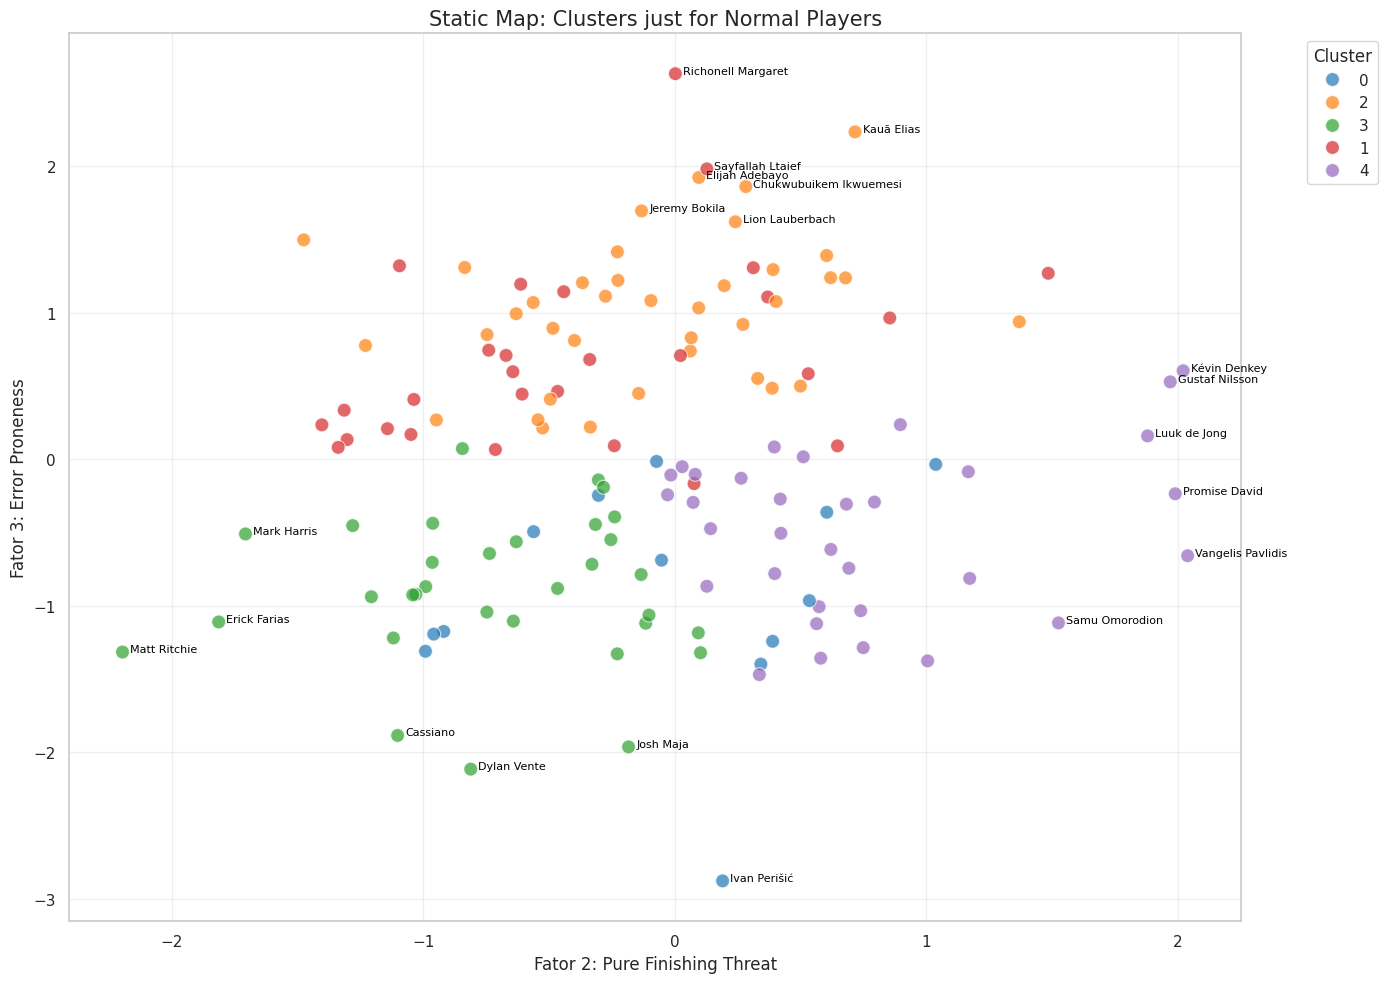

In [ ]:
plt.figure(figsize=(14, 10))

# --- FILTRAR SÓ OS NORMAIS ---
df_zoom = df_plot[df_plot['Type'] == 'Normal'].copy()

# Usar Seaborn
sns.scatterplot(data=df_zoom,
                x='Pure Finishing Threat',
                y='Error Proneness', # O eixo que pediste
                hue='Cluster',       # Cor por Cluster
                # style='Type',      # Removemos o style porque agora são todos 'Normal'
                palette='tab10',
                s=100,
                alpha=0.7)

# Adicionar nomes (Filtro ajustado para mostrar os destaques "humanos")
for i in range(df_zoom.shape[0]):
    # Mostra nome se for extremo DENTRO da escala normal (> 1.5 ou < -1.5)
    if (abs(df_zoom.iloc[i]['Pure Finishing Threat']) > 1.5) or \
       (abs(df_zoom.iloc[i]['Error Proneness']) > 1.5):

        plt.text(df_zoom.iloc[i]['Pure Finishing Threat']+0.03,
                 df_zoom.iloc[i]['Error Proneness'],
                 df_zoom.iloc[i]['Player'],
                 fontsize=8,
                 color='black')

plt.xlabel('Fator 2: Pure Finishing Threat')
plt.ylabel('Fator 3: Error Proneness')
plt.title('Static Map: Clusters just for Normal Players', fontsize=15)
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

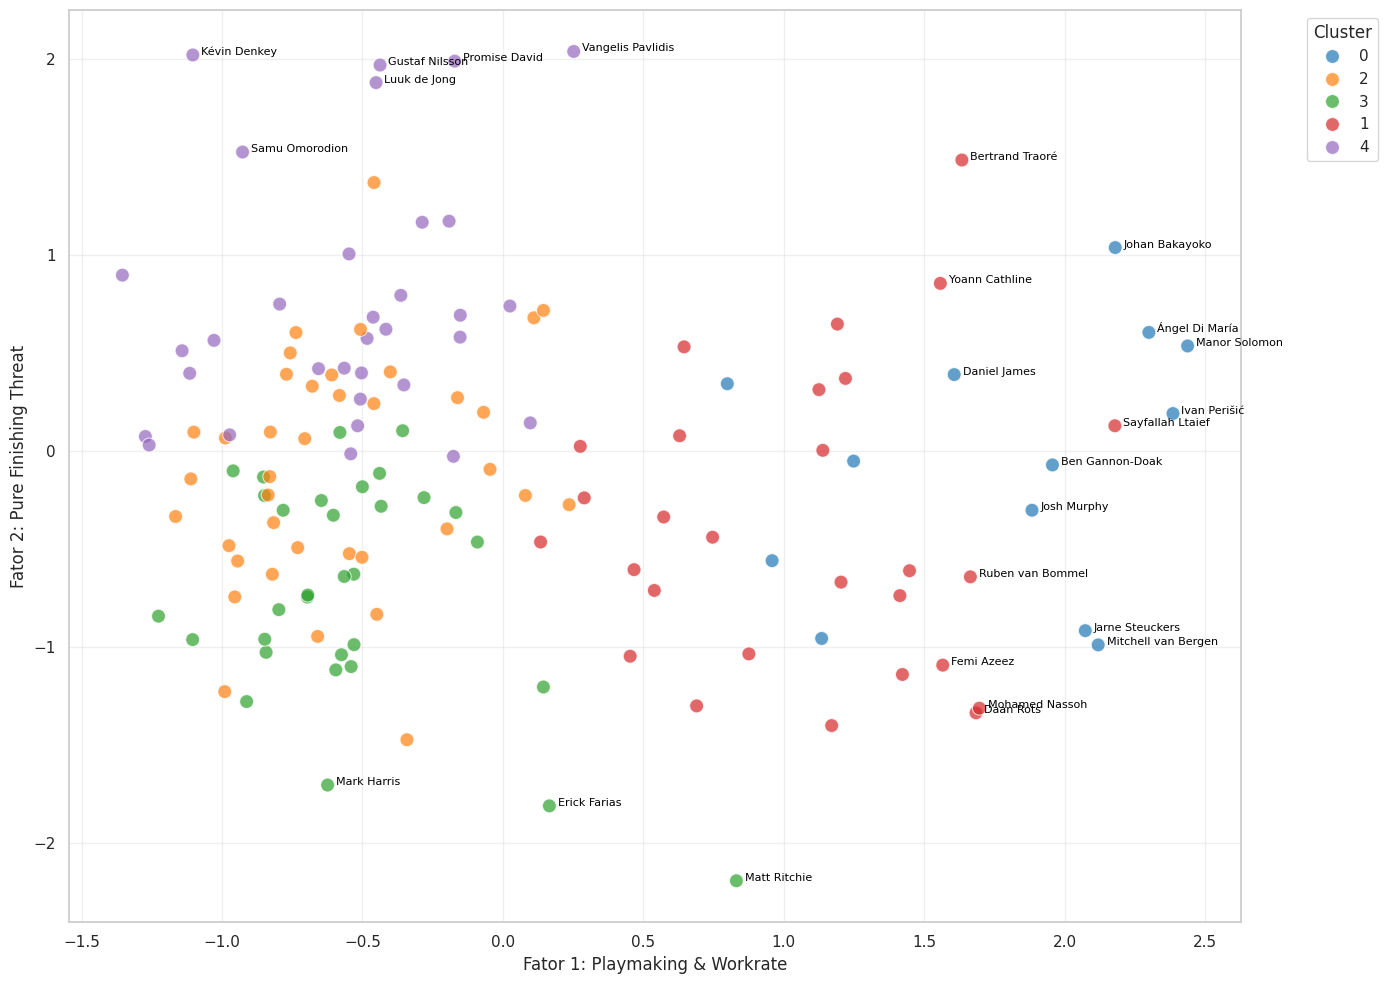

In [ ]:
plt.figure(figsize=(14, 10))

# --- FILTRAR SÓ OS NORMAIS ---
df_zoom = df_plot[df_plot['Type'] == 'Normal'].copy()

# Usar Seaborn
sns.scatterplot(data=df_zoom,
                x='Playmaking & Workrate',
                y='Pure Finishing Threat', # O eixo que pediste
                hue='Cluster',       # Cor por Cluster
                # style='Type',      # Removemos o style porque agora são todos 'Normal'
                palette='tab10',
                s=100,
                alpha=0.7)

# Adicionar nomes (Filtro ajustado para mostrar os destaques "humanos")
for i in range(df_zoom.shape[0]):
    # Mostra nome se for extremo DENTRO da escala normal (> 1.5 ou < -1.5)
    if (abs(df_zoom.iloc[i]['Playmaking & Workrate']) > 1.5) or \
       (abs(df_zoom.iloc[i]['Pure Finishing Threat']) > 1.5):

        plt.text(df_zoom.iloc[i]['Playmaking & Workrate']+0.03,
                 df_zoom.iloc[i]['Pure Finishing Threat'],
                 df_zoom.iloc[i]['Player'],
                 fontsize=8,
                 color='black')

plt.xlabel('Fator 1: Playmaking & Workrate')
plt.ylabel('Fator 2: Pure Finishing Threat')

plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Preparar os dados: Vamos fazer reset ao index para o "Nome" passar a ser uma coluna normal
# Isto cria uma coluna chamada 'index' (ou o nome que tinhas) com os nomes dos jogadores
df_interativo = factor_scores_df.reset_index()

# Garante que a coluna dos nomes se chama 'Player' (ajusta se necessário)
df_interativo = df_interativo.rename(columns={'index': 'Player', 'Equipa': 'Player'})
# (Nota: O pandas dá o nome 'index' por defeito se o index não tiver nome)

# Merge kmeans_cluster from df_8_original into df_interativo
df_interativo = df_interativo.merge(df_8_original['kmeans_cluster'], left_on='Player', right_index=True)
df_interativo = df_interativo.rename(columns={'kmeans_cluster': 'Cluster'})

# 2. Criar o Gráfico Mágico
fig = px.scatter(df_interativo,
                 x='Playmaking & Workrate',
                 y='Pure Finishing Threat',
                 color='Cluster',
                 hover_name='Player', # <--- AQUI ESTÁ A MAGIA! (Mostra o nome ao passar o rato)
                 title='Mapa Interativo dos Perfis (Passa o rato nos pontos!)',
                 template='plotly_dark', # Fica com um look "pro" escuro
                 width=1000,
                 height=700)

# 3. Melhorar o design (opcional, mas fica top)
fig.update_traces(marker=dict(size=10, line=dict(width=1, color='DarkSlateGrey')))
fig.update_layout(legend_title_text='Perfil Tático')

# 4. Mostrar
fig.show()

In [ ]:
# 1. Preparar os dados: Vamos fazer reset ao index para o "Nome" passar a ser uma coluna normal
# Isto cria uma coluna chamada 'index' (ou o nome que tinhas) com os nomes dos jogadores
df_interativo = factor_scores_df.reset_index()

# Garante que a coluna dos nomes se chama 'Player' (ajusta se necessário)
df_interativo = df_interativo.rename(columns={'index': 'Player', 'Equipa': 'Player'})
# (Nota: O pandas dá o nome 'index' por defeito se o index não tiver nome)

# Merge kmeans_cluster from df_8_original into df_interativo
df_interativo = df_interativo.merge(df_8_original['kmeans_cluster'], left_on='Player', right_index=True)
df_interativo = df_interativo.rename(columns={'kmeans_cluster': 'Cluster'})

# 2. Criar o Gráfico Mágico
fig = px.scatter(df_interativo,
                 x='Playmaking & Workrate',
                 y='Error Proneness',
                 color='Cluster',
                 hover_name='Player', # <--- AQUI ESTÁ A MAGIA! (Mostra o nome ao passar o rato)
                 title='Mapa Interativo dos Perfis (Passa o rato nos pontos!)',
                 template='plotly_dark', # Fica com um look "pro" escuro
                 width=1000,
                 height=700)

# 3. Melhorar o design (opcional, mas fica top)
fig.update_traces(marker=dict(size=10, line=dict(width=1, color='DarkSlateGrey')))
fig.update_layout(legend_title_text='Perfil Tático')

# 4. Mostrar
fig.show()

In [ ]:
# 1. Preparar os dados: Vamos fazer reset ao index para o "Nome" passar a ser uma coluna normal
# Isto cria uma coluna chamada 'index' (ou o nome que tinhas) com os nomes dos jogadores
df_interativo = factor_scores_df.reset_index()

# Garante que a coluna dos nomes se chama 'Player' (ajusta se necessário)
df_interativo = df_interativo.rename(columns={'index': 'Player', 'Equipa': 'Player'})
# (Nota: O pandas dá o nome 'index' por defeito se o index não tiver nome)

# Merge kmeans_cluster from df_8_original into df_interativo
df_interativo = df_interativo.merge(df_8_original['kmeans_cluster'], left_on='Player', right_index=True)
df_interativo = df_interativo.rename(columns={'kmeans_cluster': 'Cluster'})

# 2. Criar o Gráfico Mágico
fig = px.scatter(df_interativo,
                 x='Pure Finishing Threat',
                 y='Error Proneness',
                 color='Cluster',
                 hover_name='Player', # <--- AQUI ESTÁ A MAGIA! (Mostra o nome ao passar o rato)
                 title='Mapa Interativo dos Perfis (Passa o rato nos pontos!)',
                 template='plotly_dark', # Fica com um look "pro" escuro
                 width=1000,
                 height=700)

# 3. Melhorar o design (opcional, mas fica top)
fig.update_traces(marker=dict(size=10, line=dict(width=1, color='DarkSlateGrey')))
fig.update_layout(legend_title_text='Perfil Tático')

# 4. Mostrar
fig.show()